In [15]:
import torch
from sklearn import datasets
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt


SEED = 42


In [ ]:
iris = datasets.load_iris()

In [7]:
X, y = iris.data, iris.target

In [13]:
y.dtype

dtype('int64')

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)

In [10]:
class NeuralNet(torch.nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = torch.nn.Sequential(
            torch.nn.Linear(4, 2),
            torch.nn.ReLU(),
            torch.nn.Linear(2, 3)
        )

    def forward(self, x):
        logits = self.layers(x)

        return logits


In [14]:
X_train_tens = torch.tensor(X_train, dtype=torch.float32)
y_train_tens = torch.tensor(y_train, dtype=torch.long)

In [18]:
def fit(model):
    epochs = 400
    loss_arr = []
    loss_fn = torch.nn.CrossEntropyLoss()
    optim = torch.optim.Adam(model.parameters(), lr=0.002)

    for epoch in range(epochs):
        y_pred = model(X_train_tens)
        loss = loss_fn(y_pred, y_train_tens)
        loss_arr.append(loss.item())
        loss.backward()
        optim.step()
        optim.zero_grad()

    plt.plot(loss_arr)
    plt.show()

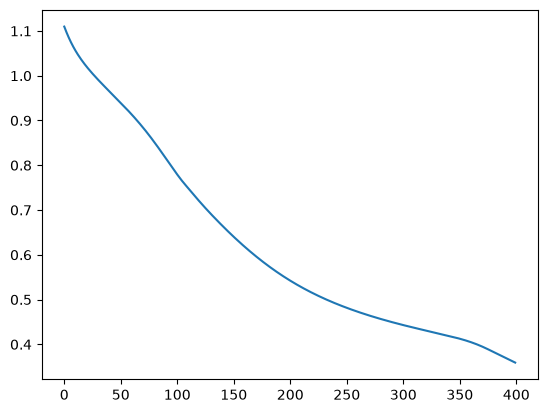

In [19]:
model = NeuralNet()
model.to("mps")
X_train_tens = X_train_tens.to("mps")
y_train_tens = y_train_tens.to("mps")

fit(model)

In [22]:
X_test_tens = torch.tensor(X_test, dtype=torch.float32).to("mps")

y_pred = model(X_test_tens)

ymaxpred = torch.argmax(y_pred, dim=1)

In [23]:
from sklearn.metrics import accuracy_score

print(f"Accuracy test: {accuracy_score(ymaxpred.cpu(), y_test)}")

Accuracy test: 0.9666666666666667


In [24]:
for p in model.parameters():
    print(p.grad)

None
None
None
None
